In [1]:
from pathlib import Path

from parcial_ml.data import load_dataset
from parcial_ml.models import fit_poly, predict_poly
import matplotlib.pyplot as plt
import pandas as pd

from parcial_ml.analysis import (
    DEGREES_EX2, SETS, best_degrees, degree_sweep, fit_all,
    grid_predictions, make_grid, mean_hypothesis_and_variance,
    mean_validation_risk, summary_table,
)

OUT = Path("../resultados")
OUT.mkdir(exist_ok=True)

# Ejercicio 1. Complejidad y generalización
### (a) 

In [2]:
tabla1 = degree_sweep()
tabla1.to_csv(OUT / "ejercicio1_tabla.csv", index=False)
tabla1

,grado,riesgo_train,riesgo_val
0,1,0.406777,0.510432
1,2,0.327561,0.441047
2,3,0.120407,0.200026
3,4,0.118253,0.201967
4,5,0.083426,0.161396
5,6,0.082978,0.164074
6,7,0.074472,0.184270
7,8,0.069638,0.189821
8,9,0.069184,0.188407
9,10,0.065834,0.222431


### b

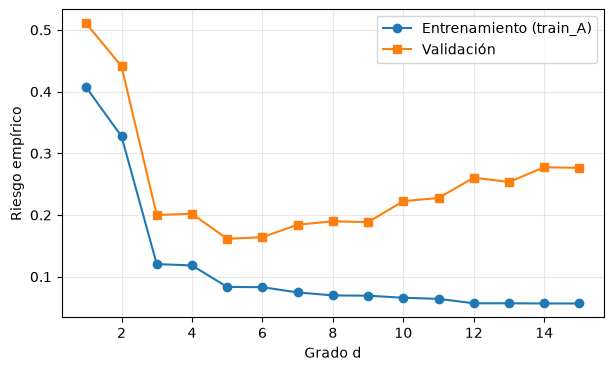

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla1["grado"], tabla1["riesgo_train"], "o-", label="Entrenamiento (train_A)")
ax.plot(tabla1["grado"], tabla1["riesgo_val"], "s-", label="Validación")
ax.set_xlabel("Grado d")
ax.set_ylabel("Riesgo empírico")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(OUT / "ejercicio1_riesgos.png", dpi=150, bbox_inches="tight")
plt.show()

### c

In [4]:
d_train, r_train, d_val, r_val = best_degrees(tabla1)
print(f"d_train = {d_train}, riesgo de entrenamiento = {r_train:.4f}")
print(f"d_val   = {d_val}, riesgo de validación   = {r_val:.4f}")

d_train = 15, riesgo de entrenamiento = 0.0565
d_val   = 5, riesgo de validación   = 0.1614


### d

In [5]:
tabla1[tabla1["grado"].isin([2, 6, 15])]

,grado,riesgo_train,riesgo_val
1,2,0.327561,0.441047
5,6,0.082978,0.164074
14,15,0.056541,0.276480


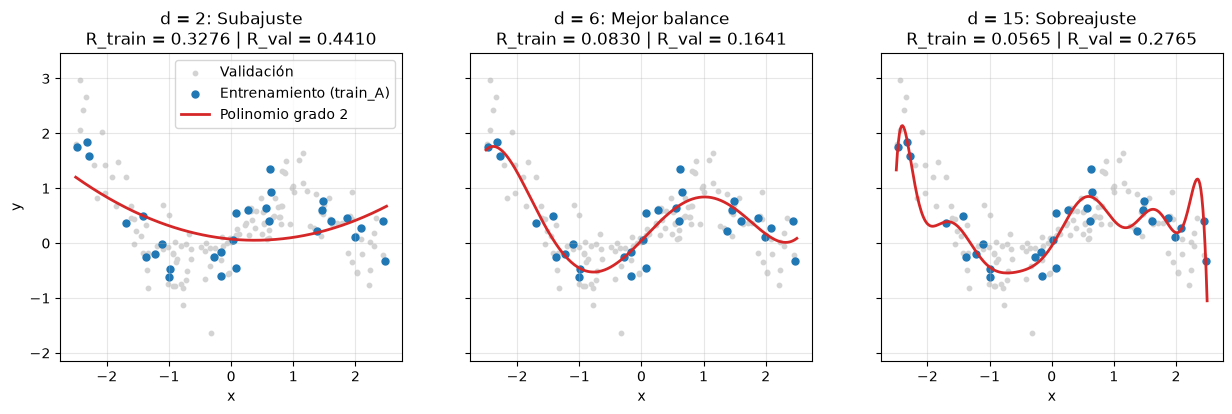

In [6]:
x_tr, y_tr = load_dataset("train_A")
x_val, y_val = load_dataset("validation")
malla = make_grid(300, -2.5, 2.5)

etiquetas = {2: "Subajuste", 6: "Mejor balance", 15: "Sobreajuste"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, [2, 6, 15]):
    modelo = fit_poly(x_tr, y_tr, d)
    fila = tabla1[tabla1["grado"] == d].iloc[0]
    ax.scatter(x_val, y_val, s=10, color="lightgray", label="Validación")
    ax.scatter(x_tr, y_tr, s=25, color="tab:blue", label="Entrenamiento (train_A)")
    ax.plot(malla, predict_poly(modelo, malla), color="tab:red", lw=2, label=f"Polinomio grado {d}")
    ax.set_title(f"d = {d}: {etiquetas[d]}\n"
                 f"R_train = {fila['riesgo_train']:.4f} | R_val = {fila['riesgo_val']:.4f}")
    ax.set_xlabel("x")
    ax.set_ylim(y_val.min() - 0.5, y_val.max() + 0.5)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("y")
axes[0].legend()
fig.savefig(OUT / "ejercicio1_ajustes.png", dpi=150, bbox_inches="tight")
plt.show()

**Asociación de los grados con subajuste, mejor balance y sobreajuste**

- **d = 2: subajuste.** Tiene los riesgos más altos de los tres grados, tanto en entrenamiento (0.3276) como en validación (0.4410). El polinomio es demasiado simple para la forma de los datos y falla incluso en los puntos con los que se ajustó, como se ve en la gráfica, donde la curva queda lejos de los puntos.

- **d = 6: mejor balance.** Tiene el menor riesgo de validación de los tres grados (0.1641) y un riesgo de entrenamiento bajo (0.0830). La diferencia entre ambos es moderada.

- **d = 15: sobreajuste.** Tiene el menor riesgo de entrenamiento (0.0565), pero su riesgo de validación sube a 0.2765, mucho más que el de d = 6. La diferencia entre validación y entrenamiento es de 0.22, la más grande de los tres, lo que indica que el modelo se ajustó al ruido de train_A y generaliza peor con datos nuevos. En la gráfica, la curva se ajusta para acercarse a los puntos de entrenamiento.

En conclusión, aumentar el grado siempre reduce el riesgo de entrenamiento, pero el riesgo de validación no mejora de forma continua: el grado que mejor generaliza no es el de menor riesgo de entrenamiento.

# Ejercicio 2. Sensibilidad a la muestra

In [7]:
modelos = fit_all()                      # 9 modelos: 3 conjuntos x 3 grados
malla = make_grid(300, -2.5, 2.5)
preds = grid_predictions(modelos, malla)
hbar, Vd = mean_hypothesis_and_variance(preds)

### a

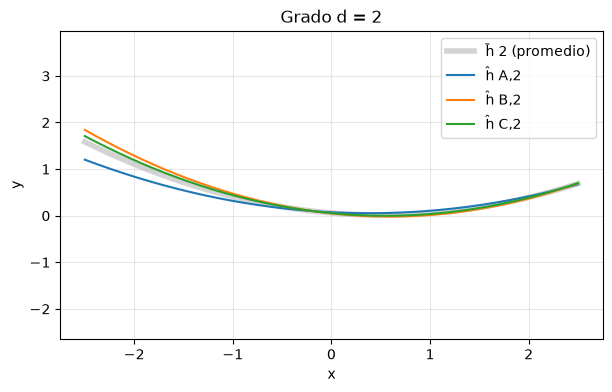

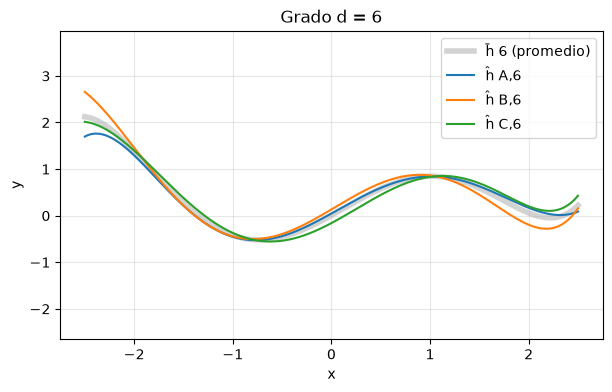

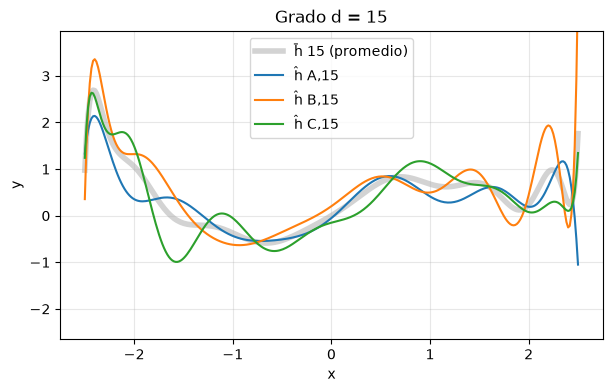

In [8]:
for d in DEGREES_EX2:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(malla, hbar[d], color="lightgray", lw=4, label=f"h̄ {d} (promedio)", zorder=1)
    for k, s in enumerate(SETS):
        ax.plot(malla, preds[d][k], label=f"ĥ {s[-1]},{d}", zorder=2)
    ax.set_title(f"Grado d = {d}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_ylim(y_val.min() - 1, y_val.max() + 1)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.savefig(OUT / f"ejercicio2_grado{d}.png", dpi=150, bbox_inches="tight")
    plt.show()

### b

In [9]:
for d in DEGREES_EX2:
    print(f"V_{d} = {Vd[d]:.4f}")

V_2 = 0.0097
V_6 = 0.0142
V_15 = 0.1288


### c

In [10]:
orden = sorted(Vd, key=Vd.get)
print("Orden de menor a mayor V_d:", orden)
print("Más estable:", orden[0], "| Más sensible:", orden[-1])

Orden de menor a mayor V_d: [2, 6, 15]
Más estable: 2 | Más sensible: 15


El orden de menor a mayor V_d es 2 < 6 < 15 (V_2 = 0.0097, V_6 = 0.0142, V_15 = 0.1288). El modelo más estable es el de grado 2, cuyas tres curvas casi coinciden aunque cambie la muestra. El más sensible es el de grado 15, y en la gráfica las tres curvas se separan mucho, sobre todo en los extremos. Al aumentar el grado el modelo gana flexibilidad y, con solo 30 puntos por muestra, cada muestra lo lleva a una curva distinta.

### d


In [11]:
rval = mean_validation_risk(modelos)
pd.DataFrame({
    "grado": list(DEGREES_EX2),
    "Vd": [Vd[d] for d in DEGREES_EX2],
    "Rval promedio": [rval[d] for d in DEGREES_EX2],
})

,grado,Vd,Rval promedio
0,2,0.009695,0.458920
1,6,0.014151,0.164837
2,15,0.128793,0.317818


- **d = 2: alto sesgo.** Es el más estable (V_2 = 0.0097), pero su riesgo promedio de validación es el más alto (0.4589). 
- **d = 6: balance sesgo–varianza.** Tiene el menor riesgo promedio de validación (0.1648) con una varianza baja (V_6 = 0.0142). Es lo bastante flexible para seguir la tendencia sin cambiar mucho de una muestra a otra.
- **d = 15: alta varianza.** Es el más sensible a la muestra (V_15 = 0.1288) y su riesgo promedio de validación (0.3178) es casi el doble que el de d = 6.

# Ejercicio 3. Selección del modelo
### a

In [12]:
rval = mean_validation_risk(modelos)      # si ya la tienes de antes, no cambia nada
tabla3 = summary_table(rval, Vd)
tabla3.to_csv(OUT / "ejercicio3_tabla.csv", index=False)
tabla3

,grado,Rval,Vd
0,2,0.458920,0.009695
1,6,0.164837,0.014151
2,15,0.317818,0.128793


### b
Se selecciona el grado **d = 6**. Es el que tiene el menor riesgo promedio de validación (R_val(6) = 0.1648) y, a la vez, una varianza baja (V_6 = 0.0142). El grado 2 es un poco más estable (V_2 = 0.0097), pero su riesgo de validación es casi tres veces mayor (0.4589). El grado 15 tiene un riesgo de validación de 0.3178 y es el más sensible a la muestra (V_15 = 0.1288). Por eso el grado 6 es el que mejor combina buen desempeño en validación y estabilidad.

### c

In [13]:
print(f"Grado seleccionado: 6 | Grado con menor riesgo de entrenamiento en train_A: {d_train}")

Grado seleccionado: 6 | Grado con menor riesgo de entrenamiento en train_A: 15


**No.** El grado seleccionado es d = 6, mientras que el menor riesgo de entrenamiento en train_A.csv se alcanza en d = 15 (0.0565).

### d
**No**, la afirmación no es compatible con los resultados. Es cierto que d = 15 tiene el menor riesgo de entrenamiento (0.0565), pero eso no implica que sea el mejor modelo: su riesgo promedio de validación es R_val(15) = 0.3178, casi el doble que el de d = 6 (R_val(6) = 0.1648), y además es el más sensible a la muestra (V_15 = 0.1288 frente a V_6 = 0.0142). El riesgo de entrenamiento no mide qué tan bien funciona el modelo con datos nuevos, y un modelo más complejo siempre lo reduce, aunque generalice peor.